# Báo cáo phương pháp — Phát hiện sai phạm Hợp đồng lao động

Tài liệu tổng quan về phương pháp của hệ thống: bài toán, đầu vào/đầu ra, quy trình xử lý,
phương pháp từng tầng, thông số và tiêu chuẩn pháp lý áp dụng. Kết quả đánh giá chi tiết xem ở
`eval/eval_report.ipynb` (rule engine, Mốc 1); khảo sát dữ liệu xem ở `notebook/eda_report.ipynb`.

In [1]:
import os, sys
from pathlib import Path
# Chạy notebook từ thư mục bất kỳ: tìm gốc dự án (thư mục chứa data/) rồi nạp mã nguồn trong rule_engine/.
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "rule_engine"))
os.chdir(ROOT)

import yaml
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

BLUE, RED, GREEN, INK, MUTED, GRID, SURFACE = "#2a78d6", "#d03b3b", "#2e9e6b", "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "text.color": INK,
 "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED})
TH = yaml.safe_load(open("config/thresholds.yaml", encoding="utf-8"))
print("Đã nạp cấu hình. Ngưỡng cập nhật:", TH["meta"]["cap_nhat"])

Đã nạp cấu hình. Ngưỡng cập nhật: 2026-09-24


## 1. Bài toán, đầu vào và đầu ra

Hệ thống nhận một hợp đồng lao động và chỉ ra các điều khoản có dấu hiệu sai phạm, kèm căn cứ pháp lý.
Bốn loại sai phạm được xét:

| Loại | Tên | Mô tả | Tầng xử lý |
|------|-----|-------|------------|
| 1 | Trái luật (định lượng/từ khóa) | Vi phạm ngưỡng số hoặc điều cấm rõ ràng | Rule |
| 2 | Thiếu điều khoản | Thiếu nội dung bắt buộc theo Điều 21 | Rule |
| 3 | Bất lợi | Điều khoản gây thiệt hại/ràng buộc vô lý cho NLĐ | LLM |
| 4 | Mập mờ | Thiếu thông tin cụ thể hoặc dùng từ tùy nghi | LLM |

- **Đầu vào:** tệp hợp đồng `.docx` (phần kiểm tra); câu hỏi dạng văn bản (phần Hỏi–đáp).
- **Đầu ra:** danh sách vi phạm gồm slot, loại, mức độ, căn cứ pháp lý và lý do; với Hỏi–đáp là câu trả lời kèm trích dẫn điều luật.
- **Dữ liệu nền:** kho điều luật đã cắt chunk (`data/law/chunks_v3.json`), ngưỡng pháp lý (`config/thresholds.yaml`), ngân hàng điều khoản gắn nhãn cho few-shot (`data/hdld_clauses_merged.csv`).

## 2. Sơ đồ workflow

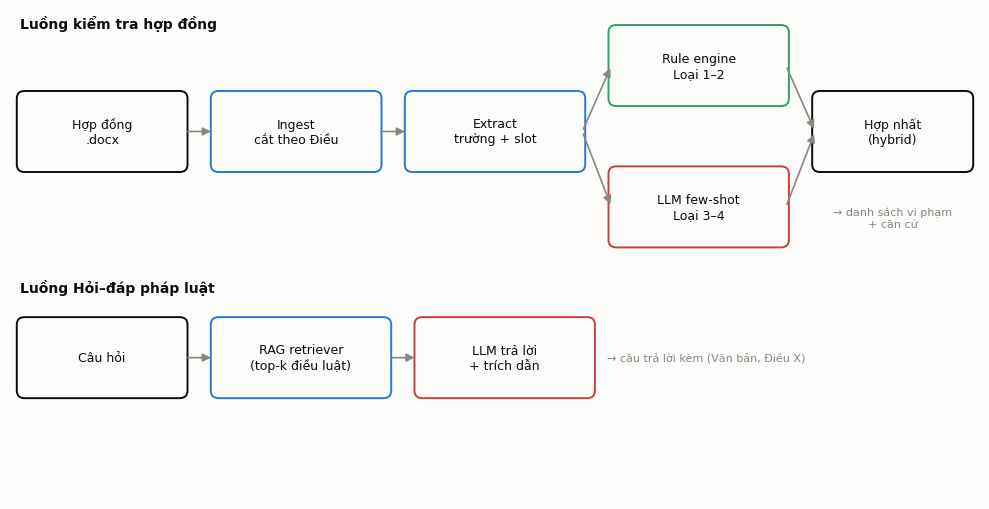

In [2]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 5.2); ax.axis("off")

def box(x, y, w, h, text, color=BLUE, fc=None):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.08",
                                linewidth=1.4, edgecolor=color, facecolor=fc or SURFACE))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9, color=INK)
    return (x, y, w, h)

def arrow(a, b, color=MUTED):
    ax.add_patch(FancyArrowPatch((a[0] + a[2], a[1] + a[3] / 2), (b[0], b[1] + b[3] / 2),
                                 arrowstyle="-|>", mutation_scale=12, linewidth=1.2, color=color))

# Luồng kiểm tra hợp đồng
hd   = box(0.1, 3.5, 1.7, 0.8, "Hợp đồng\n.docx", INK)
ing  = box(2.1, 3.5, 1.7, 0.8, "Ingest\ncắt theo Điều", BLUE)
ext  = box(4.1, 3.5, 1.8, 0.8, "Extract\ntrường + slot", BLUE)
rule = box(6.2, 4.2, 1.8, 0.8, "Rule engine\nLoại 1–2", GREEN)
llm  = box(6.2, 2.7, 1.8, 0.8, "LLM few-shot\nLoại 3–4", RED)
hyb  = box(8.3, 3.5, 1.6, 0.8, "Hợp nhất\n(hybrid)", INK)
arrow(hd, ing); arrow(ing, ext)
arrow(ext, rule); arrow(ext, llm); arrow(rule, hyb); arrow(llm, hyb)
ax.text(9.1, 3.1, "→ danh sách vi phạm\n+ căn cứ", ha="center", va="top", fontsize=8, color=MUTED)

# Luồng Hỏi–đáp
q    = box(0.1, 1.1, 1.7, 0.8, "Câu hỏi", INK)
rag  = box(2.1, 1.1, 1.8, 0.8, "RAG retriever\n(top-k điều luật)", BLUE)
qa   = box(4.2, 1.1, 1.8, 0.8, "LLM trả lời\n+ trích dẫn", RED)
arrow(q, rag); arrow(rag, qa)
ax.text(6.15, 1.5, "→ câu trả lời kèm (Văn bản, Điều X)", ha="left", va="center", fontsize=8, color=MUTED)

ax.text(0.1, 5.0, "Luồng kiểm tra hợp đồng", fontsize=10, color=INK, weight="bold")
ax.text(0.1, 2.2, "Luồng Hỏi–đáp pháp luật", fontsize=10, color=INK, weight="bold")
plt.tight_layout(); plt.show()

**Nhận xét.** Hai luồng dùng chung kho điều luật và cùng một mô hình LLM cục bộ. Ở luồng kiểm tra,
rule và LLM chạy song song trên các slot khác nhau rồi hợp nhất: rule đảm nhận phần định lượng và điều cấm
có độ chính xác cao, LLM đảm nhận phần ngữ nghĩa mở mà rule không bao phủ.

## 3. Phương pháp từng tầng

**Rule engine (Loại 1–2).** Trích các trường định lượng (lương, giờ làm, thử việc, thời hạn...) bằng regex,
ánh xạ mỗi Điều về một trong 12 slot, rồi áp dụng bộ rule viết theo điều cấm của luật: rule định lượng so với
ngưỡng trong `thresholds.yaml`, rule từ khóa khớp các dấu hiệu điều cấm, và rule thiếu điều khoản theo Điều 21.
Địa điểm làm việc được quy về tỉnh rồi về vùng lương tối thiểu; khi địa điểm mập mờ, hệ thống gắn cờ nghi ngờ
thay vì bỏ sót.

**RAG retriever.** Biểu diễn mỗi chunk điều luật bằng embedding tiếng Việt (`sentence-transformers`), truy hồi
theo cosine similarity; khi không tải được mô hình embedding sẽ tự lùi về TF-IDF. Kết quả trả về kèm số hiệu
văn bản và Điều để phục vụ trích dẫn.

**LLM phát hiện Loại 3–4.** Dùng mô hình cục bộ qua Ollama với few-shot: các ví dụ mập mờ/bất lợi/hợp lệ lấy từ
ngân hàng điều khoản và được loại khỏi tập kiểm thử để tránh rò rỉ. Prompt mặc định cả hai nhãn là false, chỉ bật
khi có dấu hiệu rõ, nhằm hạn chế gắn cờ nhầm.

**Pipeline hybrid.** Rule chạy trước cho Loại 1–2; LLM chỉ xét những slot rule chưa gắn cờ để bổ sung Loại 3–4.
Nhờ vậy phần có độ chính xác cao (rule) được giữ nguyên, phần ngữ nghĩa mở được LLM mở rộng độ phủ.

**Hỏi–đáp.** Truy hồi điều luật liên quan, dựng prompt kèm trích đoạn và ràng buộc mô hình chỉ trả lời theo trích
đoạn, luôn dẫn nguồn — hạn chế bịa nội dung hoặc số điều.

## 4. Thông số hệ thống

In [3]:
params = [
    ("Số hợp đồng mẫu", "50", "ghép từ kho câu gắn nhãn"),
    ("Số slot / hợp đồng", "12", "độ phân giải đánh giá: 50 × 12 = 600 ô"),
    ("Embedding retriever", "bkai-foundation-models/vietnamese-bi-encoder", "lùi về TF-IDF nếu không tải được"),
    ("Độ dài chunk trả về (MAX_CHARS)", "1600", "đủ để không cắt mất khoản quan trọng"),
    ("top-k truy hồi (Q&A / hybrid)", "6", "số điều luật đưa vào ngữ cảnh"),
    ("LLM cục bộ", "qwen2.5:7b (Ollama)", "temperature = 0 để ổn định"),
    ("Few-shot mập mờ/bất lợi/hợp lệ", "2 / 2 / 5", "nhiều ví dụ hợp lệ để giảm gắn cờ nhầm"),
    ("Chia dev/test", "70% / 30%, phân tầng, seed = 7", "báo số trên tập test"),
    ("Số mốc rule (stage)", "3", "baseline → bổ sung → tinh chỉnh"),
]
display(pd.DataFrame(params, columns=["Thông số", "Giá trị", "Ghi chú"]))

,Thông số,Giá trị,Ghi chú
0,Số hợp đồng mẫu,50,ghép từ kho câu gắn nhãn
1,Số slot / hợp đồng,12,độ phân giải đánh giá: 50 × 12 = 600 ô
2,Embedding retriever,bkai-foundation-models/vietnamese-bi-encoder,lùi về TF-IDF nếu không tải được
3,Độ dài chunk trả về (MAX_CHARS),1600,đủ để không cắt mất khoản quan trọng
4,top-k truy hồi (Q&A / hybrid),6,số điều luật đưa vào ngữ cảnh
5,LLM cục bộ,qwen2.5:7b (Ollama),temperature = 0 để ổn định
6,Few-shot mập mờ/bất lợi/hợp lệ,2 / 2 / 5,nhiều ví dụ hợp lệ để giảm gắn cờ nhầm
7,Chia dev/test,"70% / 30%, phân tầng, seed = 7",báo số trên tập test
8,Số mốc rule (stage),3,baseline → bổ sung → tinh chỉnh


## 5. Tiêu chuẩn pháp lý áp dụng

In [4]:
ltv = TH["luong_toi_thieu_vung"]["thang"]
rows = [
    ("Lương tối thiểu vùng I–IV (đồng/tháng)",
     f"{ltv['vung_1']:,} / {ltv['vung_2']:,} / {ltv['vung_3']:,} / {ltv['vung_4']:,}",
     TH["luong_toi_thieu_vung"]["can_cu"]),
    ("Thử việc tối đa (ngày)",
     f"quản lý {TH['thu_viec']['so_ngay_toi_da']['nguoi_quan_ly_dn']}, cao đẳng+ {TH['thu_viec']['so_ngay_toi_da']['trinh_do_cao_dang_tro_len']}",
     TH["thu_viec"]["can_cu"]),
    ("Lương thử việc tối thiểu", f"{TH['thu_viec']['luong_thu_viec_toi_thieu_phan_tram']}% lương công việc", "BLLĐ 2019, Điều 26"),
    ("Giờ làm bình thường", f"{TH['thoi_gio_lam_viec']['binh_thuong_gio_tuan']} giờ/tuần", TH["thoi_gio_lam_viec"]["can_cu"]),
    ("Làm thêm tối đa", f"{TH['thoi_gio_lam_viec']['lam_them']['gio_nam_toi_da']}–{TH['thoi_gio_lam_viec']['lam_them']['gio_nam_toi_da_dac_biet']} giờ/năm", "BLLĐ 2019, Điều 107"),
    ("Lương làm thêm (thường/nghỉ tuần/lễ)",
     f"{TH['luong_lam_them']['ngay_thuong_phan_tram']}% / {TH['luong_lam_them']['ngay_nghi_tuan_phan_tram']}% / {TH['luong_lam_them']['ngay_le_tet_phan_tram']}%",
     TH["luong_lam_them"]["can_cu"]),
    ("Hợp đồng xác định thời hạn tối đa", f"{TH['hop_dong']['xac_dinh_thoi_han_thang_toi_da']} tháng", TH["hop_dong"]["can_cu"]),
    ("Số bản hợp đồng tối thiểu", f"{TH['hop_dong']['so_ban_toi_thieu']} bản", "BLLĐ 2019, Điều 14"),
    ("Báo trước khi đơn phương chấm dứt (HĐ không xác định thời hạn)",
     f"{TH['don_phuong_cham_dut_nld_bao_truoc_ngay']['khong_xac_dinh_thoi_han']} ngày",
     TH["don_phuong_cham_dut_nld_bao_truoc_ngay"]["can_cu"]),
]
display(pd.DataFrame(rows, columns=["Tiêu chuẩn", "Ngưỡng", "Căn cứ"]))
print("Nguồn lương tối thiểu vùng:", TH["luong_toi_thieu_vung"]["nguon"])

,Tiêu chuẩn,Ngưỡng,Căn cứ
0,Lương tối thiểu vùng I–IV (đồng/tháng),"5,310,000 / 4,730,000 / 4,140,000 / 3,700,000","BLLĐ 2019, Điều 91; Nghị định 293/2025/NĐ-CP"
1,Thử việc tối đa (ngày),"quản lý 180, cao đẳng+ 60","BLLĐ 2019, Điều 24, 25, 26, 27"
2,Lương thử việc tối thiểu,85% lương công việc,"BLLĐ 2019, Điều 26"
3,Giờ làm bình thường,48 giờ/tuần,"BLLĐ 2019, Điều 105, 106, 107"
4,Làm thêm tối đa,200–300 giờ/năm,"BLLĐ 2019, Điều 107"
5,Lương làm thêm (thường/nghỉ tuần/lễ),150% / 200% / 300%,"BLLĐ 2019, Điều 98"
6,Hợp đồng xác định thời hạn tối đa,36 tháng,"BLLĐ 2019, Điều 20"
7,Số bản hợp đồng tối thiểu,2 bản,"BLLĐ 2019, Điều 14"
8,Báo trước khi đơn phương chấm dứt (HĐ không xá...,45 ngày,"BLLĐ 2019, Điều 35"


Nguồn lương tối thiểu vùng: https://vanban.chinhphu.vn/?pageid=27160&docid=215832


**Nhận xét.** Toàn bộ ngưỡng đọc trực tiếp từ `config/thresholds.yaml` nên bảng luôn khớp với cấu hình rule
đang chạy; khi luật thay đổi, chỉ cần cập nhật tệp cấu hình là cả rule lẫn báo cáo này cùng cập nhật.

## 6. Baseline: Rule-only so với Hybrid

,Phương pháp,Precision,Recall (mọi loại),F1
0,Rule-only (Loại 1–2),1.0,0.47,0.64
1,Hybrid (rule + LLM),1.0,0.96,0.98


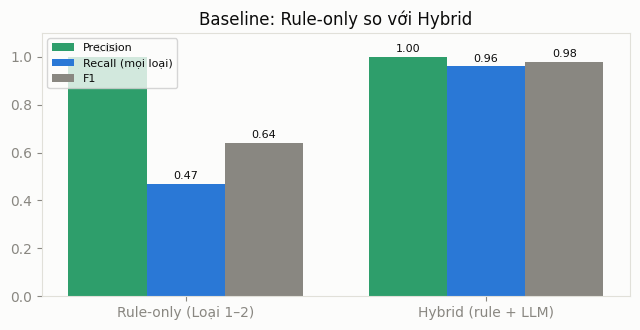

Retriever (TF-IDF): hit@1 = 0.42, hit@3 = 0.75, MRR = 0.56


In [5]:
from eval import run, metrics
by_hd, preds, gold = run()
m = metrics(by_hd, preds, gold)
P_rule, R_rule = m["precision"], m["recall_all"]
F_rule = 2 * P_rule * R_rule / (P_rule + R_rule) if P_rule + R_rule else 0

# Hybrid đo trên máy có Ollama (không chạy lại ở đây); số lấy từ lần đánh giá đã thực hiện.
P_hyb, R_hyb, F_hyb = 1.00, 0.96, 0.98

base = pd.DataFrame([
    ["Rule-only (Loại 1–2)", round(P_rule, 2), round(R_rule, 2), round(F_rule, 2)],
    ["Hybrid (rule + LLM)",  P_hyb, R_hyb, F_hyb],
], columns=["Phương pháp", "Precision", "Recall (mọi loại)", "F1"])
display(base)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = range(len(base)); w = 0.26
for i, (col, c) in enumerate([("Precision", GREEN), ("Recall (mọi loại)", BLUE), ("F1", MUTED)]):
    ax.bar([xx + i * w for xx in x], base[col], width=w, label=col, color=c)
    for xx, v in zip(x, base[col]):
        ax.text(xx + i * w, v + .02, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks([xx + w for xx in x]); ax.set_xticklabels(base["Phương pháp"]); ax.set_ylim(0, 1.1)
ax.legend(fontsize=8); ax.set_title("Baseline: Rule-only so với Hybrid"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print("Retriever (TF-IDF): hit@1 = 0.42, hit@3 = 0.75, MRR = 0.56")

**Nhận xét.** Rule-only đạt precision cao nhưng recall trên mọi loại chỉ khoảng 0.47 vì không bao phủ mập mờ
và bất lợi. Thêm tầng LLM nâng recall lên khoảng 0.96 trong khi precision vẫn giữ 1.0 trên tập mẫu. Cần lưu ý
precision 1.0 là giới hạn trên lạc quan: tập mẫu tương đối đồng nhất và prompt được tinh chỉnh trên chính tập này.

## 7. Hạn chế và hướng phát triển

1. Tập đánh giá chỉ 50 hợp đồng ghép từ cùng một kho câu, nên số liệu là giới hạn trên lạc quan; cần tập kiểm thử
   với cách diễn đạt khác để đo khả năng tổng quát.
2. Phần LLM phụ thuộc mô hình cục bộ (Ollama); chất lượng Loại 3–4 thay đổi theo mô hình và prompt.
3. Vùng lương phụ thuộc việc xác định địa điểm; địa điểm mập mờ được gắn cờ nghi ngờ thay vì kết luận chắc chắn.
4. Hướng tiếp theo: bổ sung rule cho các kiểu lỗi trái luật chưa phủ, mở rộng kho điều luật, và xây dựng tập
   kiểm thử ngoài phân phối.